# Heterogenous Ensemble — Classification (WeakestLink)

Combines diverse classifiers via **hard voting** and **soft voting**, each wrapped in bootstrap aggregation (10 bags):
- Logistic Regression
- Linear Discriminant Analysis (LDA)
- k-Nearest Neighbors (KNN)
- Random Forest

In [1]:
# Imports
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# Base classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, VotingClassifier

# MLflow
import mlflow
from dotenv import load_dotenv, find_dotenv

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

N_BAGS = 10

/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/pydantic/_internal/_fields.py:160: UserWarning: Field "model_server_url" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/pydantic/_internal/_config.py:334: UserWarning: Valid config keys have changed in V2:
* 'schema_extra' has been renamed to 'json_schema_extra'
  warnings.warn(message, UserWarning)


In [2]:
# MLflow setup
load_dotenv(find_dotenv())

EXPERIMENT_NAME = "A5_heterogenous_ensembles"
mlflow.set_experiment(EXPERIMENT_NAME)
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experiment: {EXPERIMENT_NAME}")

MLflow tracking URI: https://172.27.62.170:5001/
Experiment: A5_heterogenous_ensembles


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


## 1. Data Loading & Preprocessing

In [3]:
# Load datasets
DATA_DIR = Path("../../..") / "data/processed"
scores = pd.read_csv(DATA_DIR / "20190108_scores_and_weak_links.csv")
big = pd.read_csv(DATA_DIR / "AimoScore_WeakLink_big_scores.csv")

print("scores:", scores.shape, "big:", big.shape)

# Create WeakestLink labels
NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightAsymmetricalWeightShift"
}
indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]
scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

DROP_TIES = True
labels = scores[["ID", "WeakestLink", "HasTie"]].dropna()
if DROP_TIES:
    labels = labels.loc[~labels["HasTie"]].copy()

# Merge with features
data = big.merge(labels, on="ID", how="inner")
print("After merge:", data.shape)
print("Unique classes:", data["WeakestLink"].nunique())

# Features (38 angle + NASM deviations)
angle_cols = [f"No_{i}_Angle_Deviation" for i in range(1, 14)]
nasm_cols = [f"No_{i}_NASM_Deviation" for i in range(1, 26)]
feature_cols = angle_cols + nasm_cols

Xc = data[feature_cols].apply(pd.to_numeric, errors="coerce")
yc = data["WeakestLink"].astype(str)

# Remove singleton classes
counts = yc.value_counts()
singletons = counts[counts < 2].index
X2 = Xc.loc[~yc.isin(singletons)].copy()
y2 = yc.loc[~yc.isin(singletons)].copy()

print("Final dataset:", X2.shape)
print("Smallest class count:", int(y2.value_counts().min()))

scores: (2096, 17) big: (2094, 43)
After merge: (1724, 45)
Unique classes: 10
Final dataset: (1724, 38)
Smallest class count: 46


In [4]:
# Train/test split & CV setup
X_train, X_test, y_train, y_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y2
)

sample_weight_train = compute_sample_weight(class_weight="balanced", y=y_train)

min_class = int(y_train.value_counts().min())
cv_splits = max(2, min(5, min_class))
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_SEED)

print(f"Train: {X_train.shape[0]}, Test: {X_test.shape[0]}, CV splits: {cv_splits}")

Train: 1379, Test: 345, CV splits: 5


## 2. Define Base Classifiers

In [5]:
# Base classifiers
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        solver="lbfgs", max_iter=5000,
        class_weight="balanced", C=1.0, random_state=RANDOM_SEED
    ))
])

lda = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
])

knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5))
])

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1
    ))
])

# Wrap each in BaggingClassifier (10 bootstrap samples)
bagged_logreg = BaggingClassifier(
    estimator=logreg, n_estimators=N_BAGS,
    bootstrap=True, random_state=RANDOM_SEED, n_jobs=-1
)
bagged_lda = BaggingClassifier(
    estimator=lda, n_estimators=N_BAGS,
    bootstrap=True, random_state=RANDOM_SEED, n_jobs=-1
)
bagged_knn = BaggingClassifier(
    estimator=knn, n_estimators=N_BAGS,
    bootstrap=True, random_state=RANDOM_SEED, n_jobs=-1
)
bagged_rf = BaggingClassifier(
    estimator=rf, n_estimators=N_BAGS,
    bootstrap=True, random_state=RANDOM_SEED, n_jobs=-1
)

base_estimators = [
    ("logreg", bagged_logreg),
    ("lda", bagged_lda),
    ("knn", bagged_knn),
    ("rf", bagged_rf),
]

print(f"Base classifiers defined (each with {N_BAGS} bootstrap bags):",
      [name for name, _ in base_estimators])

Base classifiers defined (each with 10 bootstrap bags): ['logreg', 'lda', 'knn', 'rf']


## 3. Cross-Validate Individual Models

In [6]:
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

individual_results = []
fold_scores = {}  # per-fold macro-F1 for t-test

# Start parent MLflow run for the whole experiment
parent_run = mlflow.start_run(run_name="heterogenous_ensemble_experiment")
mlflow.log_param("cv_splits", cv_splits)
mlflow.log_param("random_seed", RANDOM_SEED)
mlflow.log_param("test_size", 0.2)
mlflow.log_param("drop_ties", DROP_TIES)
mlflow.log_param("n_features", len(feature_cols))
mlflow.log_param("n_bags", N_BAGS)
mlflow.log_param("base_models", [name for name, _ in base_estimators])

for name, model in base_estimators:
    out = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = float(np.mean(out[f"test_{m}"]))
        row[f"{m}_std"] = float(np.std(out[f"test_{m}"]))
    individual_results.append(row)
    fold_scores[name] = out["test_f1_macro"]

    # Log as nested MLflow run
    with mlflow.start_run(run_name=f"cv_{name}", nested=True):
        mlflow.set_tag("model_type", "individual")
        mlflow.set_tag("model_name", name)
        mlflow.log_param("n_bags", N_BAGS)
        for m in scoring:
            mlflow.log_metric(f"cv_{m}_mean", row[f"{m}_mean"])
            mlflow.log_metric(f"cv_{m}_std", row[f"{m}_std"])
        for fold_i, score in enumerate(out["test_f1_macro"]):
            mlflow.log_metric("cv_f1_macro_fold", float(score), step=fold_i)

    print(f"{name:>10s}: f1_macro={row['f1_macro_mean']:.4f} (+/- {row['f1_macro_std']:.4f})")

ind_df = pd.DataFrame(individual_results).sort_values("f1_macro_mean", ascending=False)
display(ind_df)

/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

    logreg: f1_macro=0.4885 (+/- 0.0244)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

       lda: f1_macro=0.4718 (+/- 0.0378)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarn

       knn: f1_macro=0.4368 (+/- 0.0447)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833

        rf: f1_macro=0.4645 (+/- 0.0247)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std
0,logreg,0.550408,0.022138,0.476733,0.023533,0.533667,0.030336,0.488500,0.024445,0.562722,0.021967
1,lda,0.576472,0.032016,0.500382,0.066873,0.474240,0.029711,0.471825,0.037809,0.569862,0.030053
3,rf,0.602603,0.027079,0.520256,0.034545,0.463742,0.023399,0.464500,0.024653,0.574008,0.028870
2,knn,0.556158,0.035539,0.500004,0.061134,0.425662,0.044403,0.436774,0.044737,0.544270,0.037279


## 4. Voting Ensembles

**Hard voting**: majority vote across classifiers.  
**Soft voting**: average predicted probabilities, pick argmax.

In [7]:
# Hard Voting
hard_voter = VotingClassifier(
    estimators=base_estimators,
    voting="hard",
    n_jobs=-1
)

# Soft Voting (all base models support predict_proba)
soft_voter = VotingClassifier(
    estimators=base_estimators,
    voting="soft",
    n_jobs=-1
)

ensemble_models = {
    "hard_voting": hard_voter,
    "soft_voting": soft_voter,
}

ensemble_results = []

for name, model in ensemble_models.items():
    out = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = float(np.mean(out[f"test_{m}"]))
        row[f"{m}_std"] = float(np.std(out[f"test_{m}"]))
    ensemble_results.append(row)
    fold_scores[name] = out["test_f1_macro"]

    # Log as nested MLflow run
    with mlflow.start_run(run_name=f"cv_{name}", nested=True):
        mlflow.set_tag("model_type", "ensemble")
        mlflow.set_tag("voting", name.replace("_voting", ""))
        mlflow.set_tag("model_name", name)
        for m in scoring:
            mlflow.log_metric(f"cv_{m}_mean", row[f"{m}_mean"])
            mlflow.log_metric(f"cv_{m}_std", row[f"{m}_std"])
        for fold_i, score in enumerate(out["test_f1_macro"]):
            mlflow.log_metric("cv_f1_macro_fold", float(score), step=fold_i)

    print(f"{name:>15s}: f1_macro={row['f1_macro_mean']:.4f} (+/- {row['f1_macro_std']:.4f})")

ens_df = pd.DataFrame(ensemble_results).sort_values("f1_macro_mean", ascending=False)
display(ens_df)

/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

    hard_voting: f1_macro=0.5083 (+/- 0.0364)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

    soft_voting: f1_macro=0.5171 (+/- 0.0378)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std
1,soft_voting,0.612735,0.038536,0.551445,0.059578,0.516099,0.029777,0.517081,0.037799,0.606252,0.038339
0,hard_voting,0.606922,0.036175,0.535601,0.054593,0.513442,0.029903,0.508342,0.036435,0.600884,0.036168


## 5. Compare All Models

,model,accuracy_mean,f1_macro_mean,f1_macro_std,f1_weighted_mean
4,soft_voting,0.612735,0.517081,0.037799,0.606252
5,hard_voting,0.606922,0.508342,0.036435,0.600884
0,logreg,0.550408,0.488500,0.024445,0.562722
1,lda,0.576472,0.471825,0.037809,0.569862
2,rf,0.602603,0.464500,0.024653,0.574008
3,knn,0.556158,0.436774,0.044737,0.544270


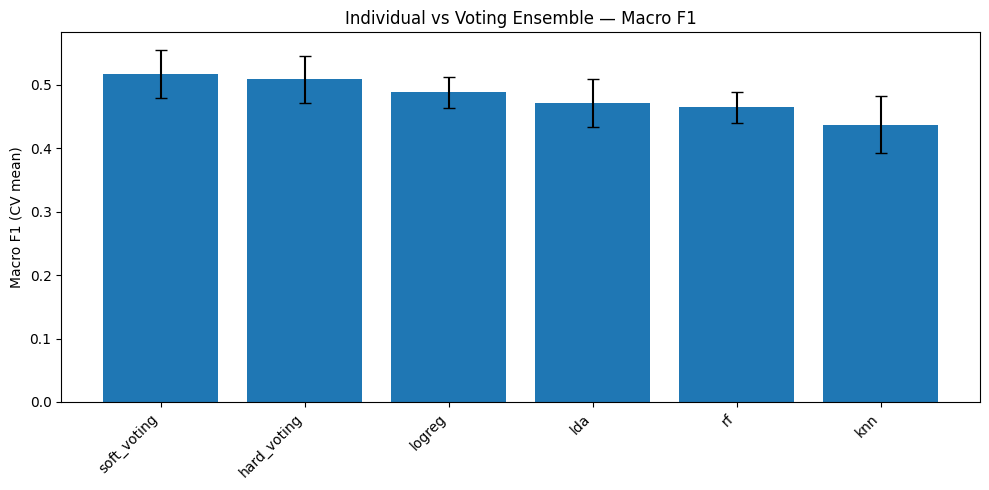

In [8]:
all_df = pd.concat([ind_df, ens_df], ignore_index=True).sort_values("f1_macro_mean", ascending=False)
display(all_df[["model", "accuracy_mean", "f1_macro_mean", "f1_macro_std", "f1_weighted_mean"]])

# Bar chart comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(all_df))
ax.bar(x, all_df["f1_macro_mean"], yerr=all_df["f1_macro_std"], capsize=4)
ax.set_xticks(list(x))
ax.set_xticklabels(all_df["model"], rotation=45, ha="right")
ax.set_ylabel("Macro F1 (CV mean)")
ax.set_title("Individual vs Voting Ensemble — Macro F1")
plt.tight_layout()
plt.show()

## 6. Statistical Significance (Paired t-test)

Paired t-test on per-fold macro-F1 scores: best ensemble vs. each other model.  
If **p < 0.05**, the difference is statistically significant.

In [9]:
# Identify best ensemble
best_ens_name = ens_df.iloc[0]["model"]
best_ens_f1 = ens_df.iloc[0]["f1_macro_mean"]
print(f"Best ensemble: {best_ens_name} (F1={best_ens_f1:.4f})\n")

# Log best ensemble CV metrics to parent run
best_ens_row = all_df[all_df["model"] == best_ens_name].iloc[0]
mlflow.log_metric("best_ensemble_f1_macro", best_ens_row["f1_macro_mean"])
mlflow.log_metric("best_ensemble_f1_weighted", best_ens_row["f1_weighted_mean"])
mlflow.set_tag("best_ensemble", best_ens_name)

# Paired t-test: best ensemble vs every other model
all_ranked = all_df.sort_values("f1_macro_mean", ascending=False)
other_models = [m for m in all_ranked["model"] if m != best_ens_name]

ttest_rows = []
for other in other_models:
    t_stat, p_value = stats.ttest_rel(fold_scores[best_ens_name], fold_scores[other])
    ttest_rows.append({
        "comparison": f"{best_ens_name} vs {other}",
        "p_value": p_value,
        "significant": "Yes" if p_value < 0.05 else "No",
    })
    # Log each p-value to MLflow
    mlflow.log_metric(f"ttest_p_{other}", p_value)

ttest_df = pd.DataFrame(ttest_rows)
display(ttest_df)

# Log all comparisons as a tag
mlflow.set_tag("ttest_comparisons", f"{best_ens_name} vs all")

Best ensemble: soft_voting (F1=0.5171)



/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverif

,comparison,p_value,significant
0,soft_voting vs hard_voting,0.535011,No
1,soft_voting vs logreg,0.075784,No
2,soft_voting vs lda,0.011108,Yes
3,soft_voting vs rf,0.041968,Yes
4,soft_voting vs knn,0.038968,Yes


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


In [10]:
# End parent MLflow run
mlflow.end_run()
print("MLflow parent run ended.")

MLflow parent run ended.


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


## 7. Champion Comparison — A4 LightGBM vs Best Ensemble

Cross-validate the A4 champion on the **same folds** to get paired per-fold macro F1 scores, then use a **paired t-test** to assess whether the difference is statistically significant.

In [11]:
import joblib

# ── 1. Load A4 champion and cross-validate on the same folds ─────────────────
A4_MODEL_PATH = Path("../../../../trained_models/A4/weakest_link_model/champion_model.joblib")
a4_champion = joblib.load(A4_MODEL_PATH)

a4_cv = cross_validate(
    a4_champion, X_train, y_train,
    cv=cv, scoring={"f1_macro": "f1_macro"}, n_jobs=-1
)
a4_fold_f1 = a4_cv["test_f1_macro"]

# Soft voting per-fold scores are already in fold_scores["soft_voting"]
ens_fold_f1 = fold_scores["soft_voting"]

# ── 2. Paired t-test ──────────────────────────────────────────────────────────
t_stat, p_value = stats.ttest_rel(a4_fold_f1, ens_fold_f1)

# ── 3. Summary ────────────────────────────────────────────────────────────────
print(f"{'Model':<30s}  {'Macro F1 mean':>14}  {'± std':>8}")
print("-" * 58)
print(f"{'LightGBM Champion (A4)':<30s}  {np.mean(a4_fold_f1):>14.4f}  {np.std(a4_fold_f1):>8.4f}")
print(f"{'Soft Voting Ensemble (A5)':<30s}  {np.mean(ens_fold_f1):>14.4f}  {np.std(ens_fold_f1):>8.4f}")
print("-" * 58)
print(f"\nPaired t-test (A4 vs A5):  t = {t_stat:.4f},  p = {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    winner = "LightGBM (A4)" if np.mean(a4_fold_f1) > np.mean(ens_fold_f1) else "Soft Voting Ensemble (A5)"
    print(f"Significant difference (p < {alpha}). {winner} is statistically better.")
else:
    print(f"No significant difference (p >= {alpha}). Champion remains: LightGBM (A4).")


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/utils/vali

Model                            Macro F1 mean     ± std
----------------------------------------------------------
LightGBM Champion (A4)                  0.5125    0.0233
Soft Voting Ensemble (A5)               0.5171    0.0378
----------------------------------------------------------

Paired t-test (A4 vs A5):  t = -0.3632,  p = 0.7348
No significant difference (p >= 0.05). Champion remains: LightGBM (A4).


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
